<a href="https://colab.research.google.com/github/DuyBach2003/K4-Track-4-Day10-VisionLanguageModel/blob/main/lab_day10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đoàn Duy Bách · MSSV 2A202602515

Mã của mình nằm trong `lab/` (đề không cho sửa `scripts/` và `tests/`):

| File | Bước GUIDE |
|---|---|
| `lab/labels.py` | 2: YOLO → JSON 0–1000 / pixel, prompt |
| `lab/vlm.py` | 3–7: nạp 4-bit, `encode_example` + mask loss, `collate`, `apply_setup`, vòng train, suy luận |
| `lab/run.py` | CLI `train` / `predict` / `score` cho E0–E4 |
| `lab/reward.py`, `lab/grpo.py` | 9: reward IoU và GRPO (E5) |
| `lab/viz.py`, `lab/summarize.py` | ảnh minh hoạ, bảng tổng hợp cho REPORT |

Mỗi thí nghiệm chạy bằng một tiến trình `python -m lab.run ...` riêng để giải phóng VRAM giữa các lần.
`work/` trỏ lên Google Drive: bị ngắt thì chạy lại **đúng ô đó**, train tự tiếp tục từ checkpoint gần nhất (mỗi 100 bước), suy luận bỏ qua ảnh đã xong.

## 0. Môi trường (Colab T4)

In [ ]:
# Runtime → Change runtime type → T4 GPU
!nvidia-smi -L
from google.colab import drive
drive.mount('/content/drive')

GPU 0: Tesla T4 (UUID: GPU-b262ecc2-f9b6-1bf5-74f6-495f5df27dca)
Mounted at /content/drive


In [ ]:
import os, subprocess
REPO_URL = 'https://github.com/DuyBach2003/K4-Track-4-Day10-VisionLanguageModel.git'
REPO = '/content/lab10'
DRIVE_WORK = '/content/drive/MyDrive/day10_work'     # adapter, dự đoán, log: sống sót khi mất session
def sh(cmd): subprocess.run(cmd, shell=True, check=True)
if not os.path.exists(REPO):
    sh(f'git clone -q {REPO_URL} {REPO}')
os.chdir(REPO)
sh('git pull -q')
os.makedirs(DRIVE_WORK, exist_ok=True)
if not os.path.islink('work'):
    sh(f'rm -rf work && ln -s {DRIVE_WORK} work')
sh('pip -q install -r requirements-colab.txt')
# torchao 0.10 cài sẵn trên Colab làm peft 0.21.2 báo ImportError (cần ≥ 0.16); lab không dùng torchao.
sh('pip -q uninstall -y torchao')
# Tuỳ chọn: HF_TOKEN trong Colab Secrets giúp tải model nhanh hơn. KHÔNG ghi khoá vào notebook.
try:
    from google.colab import userdata
    os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')
except Exception:
    pass

## 1. Dữ liệu: tải và chia split theo phiên quay

In [ ]:
# Dataset công khai (MIT): tải thẳng zip, không cần khoá Kaggle. Thư mục tạm để ngoài Drive cho nhanh.
!python scripts/prepare_data.py --zip https://www.kaggle.com/api/v1/datasets/download/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes --work /content/dl
!python -m pytest -q
!python -m pytest -q lab/tests

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}
...........................s.........................................    [100%]
68 passed, 1 skipped in 0.74s
..........................                                               [100%]
26 passed in 0.23s


In [ ]:
import collections
from scripts.labcommon import read_jsonl
sp = {s: read_jsonl(f'data/splits/{s}.jsonl') for s in ('train', 'val', 'test')}
for s, E in sp.items():
    c = collections.Counter(o['label'] for e in E for o in e['objects'])
    print(f"{s:5s} {len(E):4d} ảnh  {dict(c)}  phiên={len({e['session'] for e in E})}")
sess = {s: {e['session'] for e in E} for s, E in sp.items()}
assert not (sess['train'] & sess['val'] or sess['train'] & sess['test'] or sess['val'] & sess['test'])
print('không phiên nào nằm ở hai split')
print('phiên trong test:', collections.Counter(e['session'] for e in sp['test']))

train 1422 ảnh  {'manhole': 691, 'pothole': 1074, 'crack': 1750}  phiên=13
val    276 ảnh  {'crack': 470, 'manhole': 103, 'pothole': 66}  phiên=2
test   311 ảnh  {'crack': 299, 'manhole': 163, 'pothole': 121}  phiên=3
không phiên nào nằm ở hai split
phiên trong test: Counter({'vlc-2025-02-18-23': 213, 'vlc-2025-02-19-17': 83, 'num-4': 15})


wrote report/figures/data_samples.png


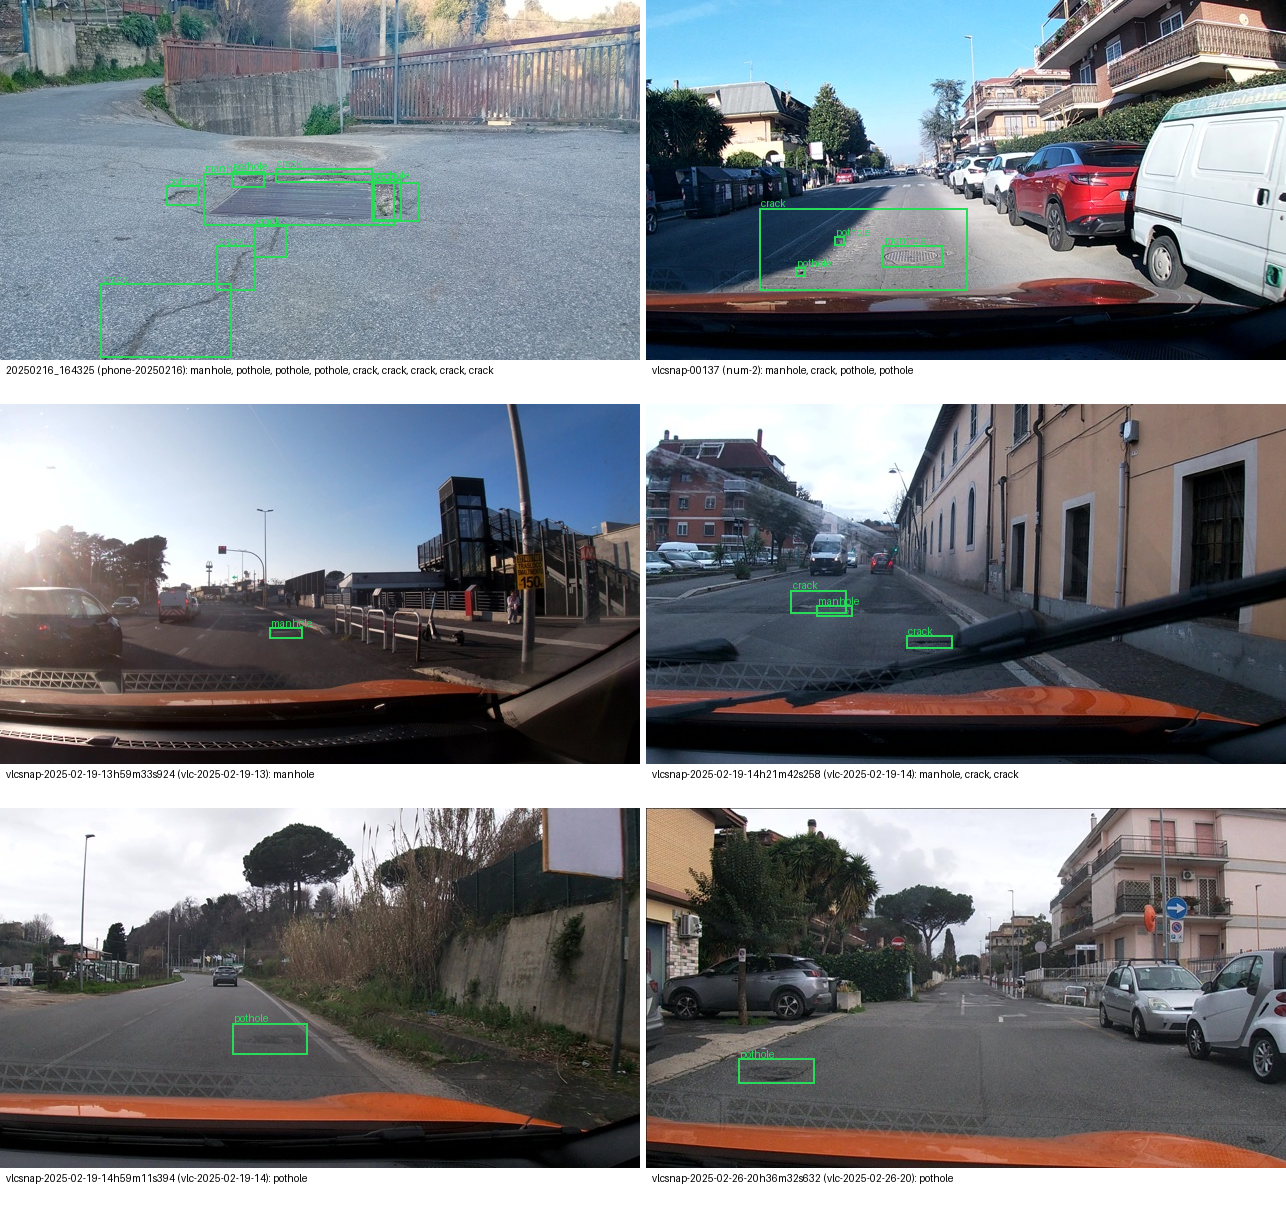

In [ ]:
!python -m lab.viz data --out report/figures/data_samples.png
from IPython.display import Image as Show
Show('report/figures/data_samples.png', width=900)

## 2. Nhãn: YOLO → JSON thang 0–1000

In [ ]:
from lab.labels import build_prompt, objects_to_answer, yolo_to_box, box_to_pixel
e = sp['train'][0]
print(build_prompt())
print(objects_to_answer(e['objects']))
print(objects_to_answer(e['objects'], 'pixel'))
# quy ngược về pixel: phải trùng box gốc (sai số làm tròn < 1 px)
for o in e['objects']:
    xc, yc, w, h = o['yolo']
    back = box_to_pixel(yolo_to_box(o['label'], o['yolo'])['bbox_2d'])
    orig = ((xc - w/2) * 640, (yc - h/2) * 360, (xc + w/2) * 640, (yc + h/2) * 360)
    print(o['label'], [round(v, 1) for v in back], 'sai lệch tối đa', round(max(abs(x - y) for x, y in zip(back, orig)), 2), 'px')

You are inspecting a dashcam image of a road. Detect every instance of road damage from exactly these classes: pothole, crack, manhole.
Coordinates are integers on a 0-1000 scale relative to the image (0 = left/top edge, 1000 = right/bottom edge).
Answer with ONLY a JSON list, no markdown and no extra text, in the form [{"label": "pothole", "bbox_2d": [x1, y1, x2, y2]}], where (x1, y1) is the top-left and (x2, y2) the bottom-right corner. Return [] if there is no damage.
[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]
[{"label":"crack","bbox_2d":[275,168,373,182]},{"label":"pothole","bbox_2d":[231,171,265,188]},{"lab

## 3. E0: zero-shot

In [ ]:
!python -m lab.run predict --name e0 --zero-shot
!python -m lab.run score --name e0

preprocessor_config.json: 100% 390/390 [00:00<00:00, 953kB/s]
chat_template.json: 100% 5.50k/5.50k [00:00<00:00, 12.0MB/s]
config.json: 100% 1.50k/1.50k [00:00<00:00, 3.53MB/s]
tokenizer_config.json: 100% 10.9k/10.9k [00:00<00:00, 22.8MB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 55.7MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 76.7MB/s]
tokenizer.json: 100% 7.03M/7.03M [00:00<00:00, 74.0MB/s]
video_preprocessor_config.json: 100% 385/385 [00:00<00:00, 1.13MB/s]
model.safetensors.index.json: 100% 64.7k/64.7k [00:00<00:00, 121MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0% 0/2 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/8.88G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):   0% 0.00/8.88G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   5% 402M/8.88G [00:22<03:07, 45.3MB/s, 45.3MB/s  ]
Reconstructing (incomplete total...):  16% 1.43G/8.88G [01:02<03:43, 33.3MB/s, 33.3MB/s  ]
Rec

In [ ]:
from scripts.score import parse_output
rows = read_jsonl('work/e0_test.jsonl')
for r in rows[:5]:
    print(r['image_id'], repr(r['raw'][:300]), '\n')
bad = [r for r in rows if parse_output(r['raw']) is None]
print(f'{len(bad)} output không parse được; ví dụ:', [b['raw'][:200] for b in bad[:3]])

vlcsnap-00200 '[{"label": "manhole", "bbox_2d": [770, 638, 843, 684]}, {"label": "manhole", "bbox_2d": [909, 786, 998, 824]}]' 

vlcsnap-00201 '[]' 

vlcsnap-00202 '[{"label": "manhole", "bbox_2d": [297, 684, 399, 719]}]' 

vlcsnap-00203 '[]' 

vlcsnap-00204 '[{"label": "manhole", "bbox_2d": [253, 624, 325, 658]}]' 

16 output không parse được; ví dụ: ['[{"label": "crack", "bbox_2d": [52, 624, 197, 686]}, {"label": "crack", "bbox_2d": [197, 624, 333, 686]}, {"label": "crack", "bbox_2d": [333, 624, 470, 686]}, {"label": "crack", "bbox_2d": [470, 624, ', '[{"label": "manhole", "bbox_2d": [51, 596, 193, 654]}, {"label": "manhole", "bbox_2d": [890, 700, 1000, 776)}]', '[{"label": "crack", "bbox_2d": [559, 370, 600, 400]}, {"label": "crack", "bbox_2d": [650, 538, 700, 560]}, {"label": "crack", "bbox_2d": [739, 470, 789, 490]}, {"label": "crack", "bbox_2d": [739, 470,']


## 4. Dữ liệu huấn luyện: chat template và mask loss

In [ ]:
import torch
from PIL import Image
from lab import vlm
proc = vlm.load_processor(padding_side='right')
ex = vlm.encode_example(proc, Image.open('data/' + e['image_path']), build_prompt(), objects_to_answer(e['objects']))
img_tok = proc.tokenizer.convert_tokens_to_ids('<|image_pad|>')
print('token ảnh:', (ex['input_ids'] == img_tok).sum().item())            # phải là 220
print('tổng token:', ex['input_ids'].shape[1], '| token có loss:', (ex['labels'] != -100).sum().item())
print('phần học:', repr(proc.tokenizer.decode(ex['input_ids'][ex['labels'] != -100])))
b = vlm.collate([ex, vlm.SFTDataset(sp['train'][1:2], 'data', proc)[0]], proc.tokenizer.pad_token_id)
print({k: tuple(v.shape) for k, v in b.items()})

token ảnh: 220
tổng token: 625 | token có loss: 250
phần học: '[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>\n'
{'input_ids': (2, 625), 'attention_mask': (2, 625), 'mm_token_type_ids': (2, 625), 'labels': (2, 625), 'pixel_values': (1760, 1536), 'image_grid_thw': (2, 3)}


## 5. Setup LoRA / đóng băng cho E1, E2, E3 (đếm trên meta device, không tốn VRAM)

In [ ]:
from accelerate import init_empty_weights
from transformers import AutoConfig, Qwen3VLForConditionalGeneration
from lab.run import load_cfg!pip -q uninstall -y torchao
!pip -q uninstall -y torchao
cfg = AutoConfig.from_pretrained(vlm.MODEL_ID)
for name in ('e1', 'e2', 'e3'):
    c = load_cfg(f'configs/{name}.yaml')
    with init_empty_weights():
        m = Qwen3VLForConditionalGeneration._from_config(cfg)
    _, info = vlm.apply_setup(m, c['lora'], c['train_projector'])
    print(name, info)

## 6. Vòng huấn luyện
Mỗi ô dưới đây chạy trọn một thí nghiệm: train (`lab.vlm.train`, ≈ 20–35 phút) → suy luận test → chấm. Gỡ lỗi trước trên 40 ảnh val nếu muốn: `predict --split val --limit 40` rồi `score --split val`.

In [ ]:
!python -m lab.run train --name e1 --config configs/e1.yaml
!python -m lab.run predict --name e1
!python -m lab.run score --name e1

In [ ]:
!python -m lab.run train --name e2 --config configs/e2.yaml
!python -m lab.run predict --name e2
!python -m lab.run score --name e2

In [ ]:
!python -m lab.run train --name e3 --config configs/e3.yaml
!python -m lab.run predict --name e3
!python -m lab.run score --name e3

## 7. Suy luận và chấm E1–E3: đường loss, ảnh minh hoạ, bảng tổng hợp

In [ ]:
import json, matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 3.5))
for name in ('e1', 'e2', 'e3'):
    if not os.path.exists(f'work/{name}/train_log.jsonl'):
        print('thiếu log của', name); continue
    log = read_jsonl(f'work/{name}/train_log.jsonl')
    ax.plot([r['step'] for r in log], [r['loss'] for r in log], label=name.upper(), lw=1)
ax.set_xlabel('bước'); ax.set_ylabel('loss'); ax.legend(); ax.set_yscale('log')
fig.tight_layout(); fig.savefig('report/figures/train_loss.png', dpi=120)
for name in ('e0', 'e1', 'e2', 'e3'):
    !python -m lab.viz pred --name {name} --out report/figures/{name}_examples.png
!python -m lab.summarize

In [ ]:
Show('report/figures/e1_examples.png', width=900)

## 8. E4: ablation (đổi đúng một biến so với setup tốt nhất)
`BEST` được chọn tự động là setup có F1 test cao nhất trong E1–E3. Mặc định chọn biến **thang toạ độ**: giá trị `norm1000` chính là setup gốc (dùng lại dự đoán của `BEST`), chỉ cần train thêm `pixel`.
Muốn đổi biến khác: `--set lora.r=4 --set lora.alpha=8` / `--set lora.r=64 --set lora.alpha=128`, hoặc `--set train_fraction=0.1`.

In [ ]:
f1 = {n: json.load(open(f'report/evidence/{n}.json'))['micro']['f1']
      for n in ('e1', 'e2', 'e3') if os.path.exists(f'report/evidence/{n}.json')}
BEST = max(f1, key=f1.get)
print({k: round(v, 3) for k, v in f1.items()}, '→ BEST =', BEST)
!python -m lab.run train --name e4_coord_scale_pixel --config configs/{BEST}.yaml --set coord=pixel
!python -m lab.run predict --name e4_coord_scale_pixel
!python -m lab.run score --name e4_coord_scale_pixel
!python -m lab.run score --name e4_coord_scale_norm1000 --pred-from {BEST}
!python -m lab.viz pred --name e4_coord_scale_pixel --coord pixel --out report/figures/e4_pixel_examples.png
!python -m lab.summarize
# sao lưu kết quả chính lên Drive trước khi chạy E5 (tuỳ chọn)
!rm -rf /content/drive/MyDrive/day10_report && cp -r report /content/drive/MyDrive/day10_report

## 9. E5 (tuỳ chọn): GRPO với reward IoU
Hàm reward và test: `lab/reward.py`, `lab/tests/test_reward.py` (đã chạy ở bước 1).

In [ ]:
!python -m lab.grpo --init {BEST} --name e5 --config configs/e5.yaml
!python -m lab.run predict --name e5
!python -m lab.run score --name e5 --out report/evidence/e5.json

In [ ]:
if not (os.path.exists('work/e5/grpo_log.jsonl') and os.path.exists('work/e5_test.jsonl')):
    print('E5 chưa chạy xong: bỏ qua phân tích')   # không chặn ô tải report bên dưới
else:
    log = read_jsonl('work/e5/grpo_log.jsonl')
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].plot([r['step'] for r in log], [r['reward'] for r in log]); ax[0].set_title('reward trung bình')
    ax[1].plot([r['step'] for r in log], [r['completions/mean_length'] for r in log]); ax[1].set_title('độ dài completion')
    fig.tight_layout(); fig.savefig('report/figures/e5_grpo.png', dpi=120)
    # dấu hiệu reward hacking: tỉ lệ trả [] hoặc box khổng lồ
    from scripts.score import parse_output
    for name in (BEST, 'e5'):
        P = [parse_output(r['raw']) for r in read_jsonl(f'work/{name}_test.jsonl')]
        empty = sum(p == [] for p in P); big = sum(1 for p in P if p for b in p if (b['bbox'][2]-b['bbox'][0])*(b['bbox'][3]-b['bbox'][1]) > 0.25e6)
        print(name, 'trả []:', empty, '| box > 25% khung hình:', big, '| box/ảnh:', sum(len(p or []) for p in P) / len(P))

## Lưu kết quả về repo
Ô dưới tải `report.zip` về máy; bản sao cũng nằm ở `MyDrive/day10_report`. Giải nén đè lên thư mục `report/` của repo rồi commit (đừng commit `work/`, `data/`).

In [ ]:
!python -m lab.summarize
!rm -rf /content/drive/MyDrive/day10_report && cp -r report /content/drive/MyDrive/day10_report
!zip -qr report.zip report
from google.colab import files
files.download('report.zip')